In [1]:
# Abraham_202431041
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
# Abraham_202431041
df = pd.read_csv('01_heart_disease.csv')

print("--- 5 Baris Pertama Dataset ---")
display(df.head())

print("\n--- Informasi Dataset ---")
print(df.info())

--- 5 Baris Pertama Dataset ---


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0



--- Informasi Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB
None


--- Missing Values ---
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

--- Statistik Deskriptif ---


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


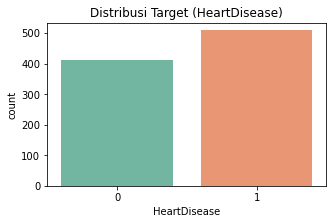

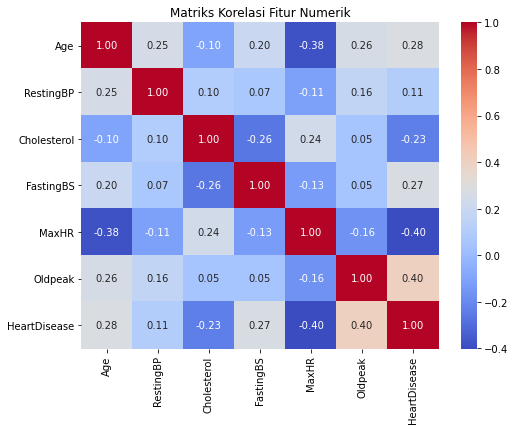

In [3]:
# Abraham_202431041
print("--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Statistik Deskriptif ---")
display(df.describe())

plt.figure(figsize=(5, 3))
sns.countplot(x='HeartDisease', data=df, palette='Set2')
plt.title('Distribusi Target (HeartDisease)')
plt.show()

plt.figure(figsize=(8, 6))
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriks Korelasi Fitur Numerik')
plt.show()

In [6]:
# Abraham_202431041
X = df.drop(columns=['HeartDisease'])
y = df['HeartDisease']

categorical_cols = X.select_dtypes(include=['object']).columns
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns

print("Kolom Kategorikal:", list(categorical_cols))
print("Kolom Numerik:", list(numerical_cols))

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first'), categorical_cols)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nJumlah Data Latih: {X_train.shape[0]} baris")
print(f"Jumlah Data Uji: {X_test.shape[0]} baris")

Kolom Kategorikal: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Kolom Numerik: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']

Jumlah Data Latih: 734 baris
Jumlah Data Uji: 184 baris


=== Model Decision Tree ===
Akurasi: 0.7989

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.77      0.77        82
           1       0.82      0.82      0.82       102

    accuracy                           0.80       184
   macro avg       0.80      0.80      0.80       184
weighted avg       0.80      0.80      0.80       184



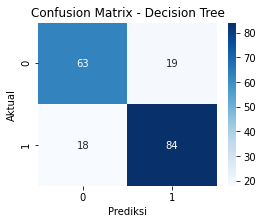

In [7]:
# Abraham_202431041
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42, max_depth=5))
])

dt_pipeline.fit(X_train, y_train)

y_pred_dt = dt_pipeline.predict(X_test)
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("=== Model Decision Tree ===")
print(f"Akurasi: {dt_accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_dt))

plt.figure(figsize=(4, 3))
sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Decision Tree')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

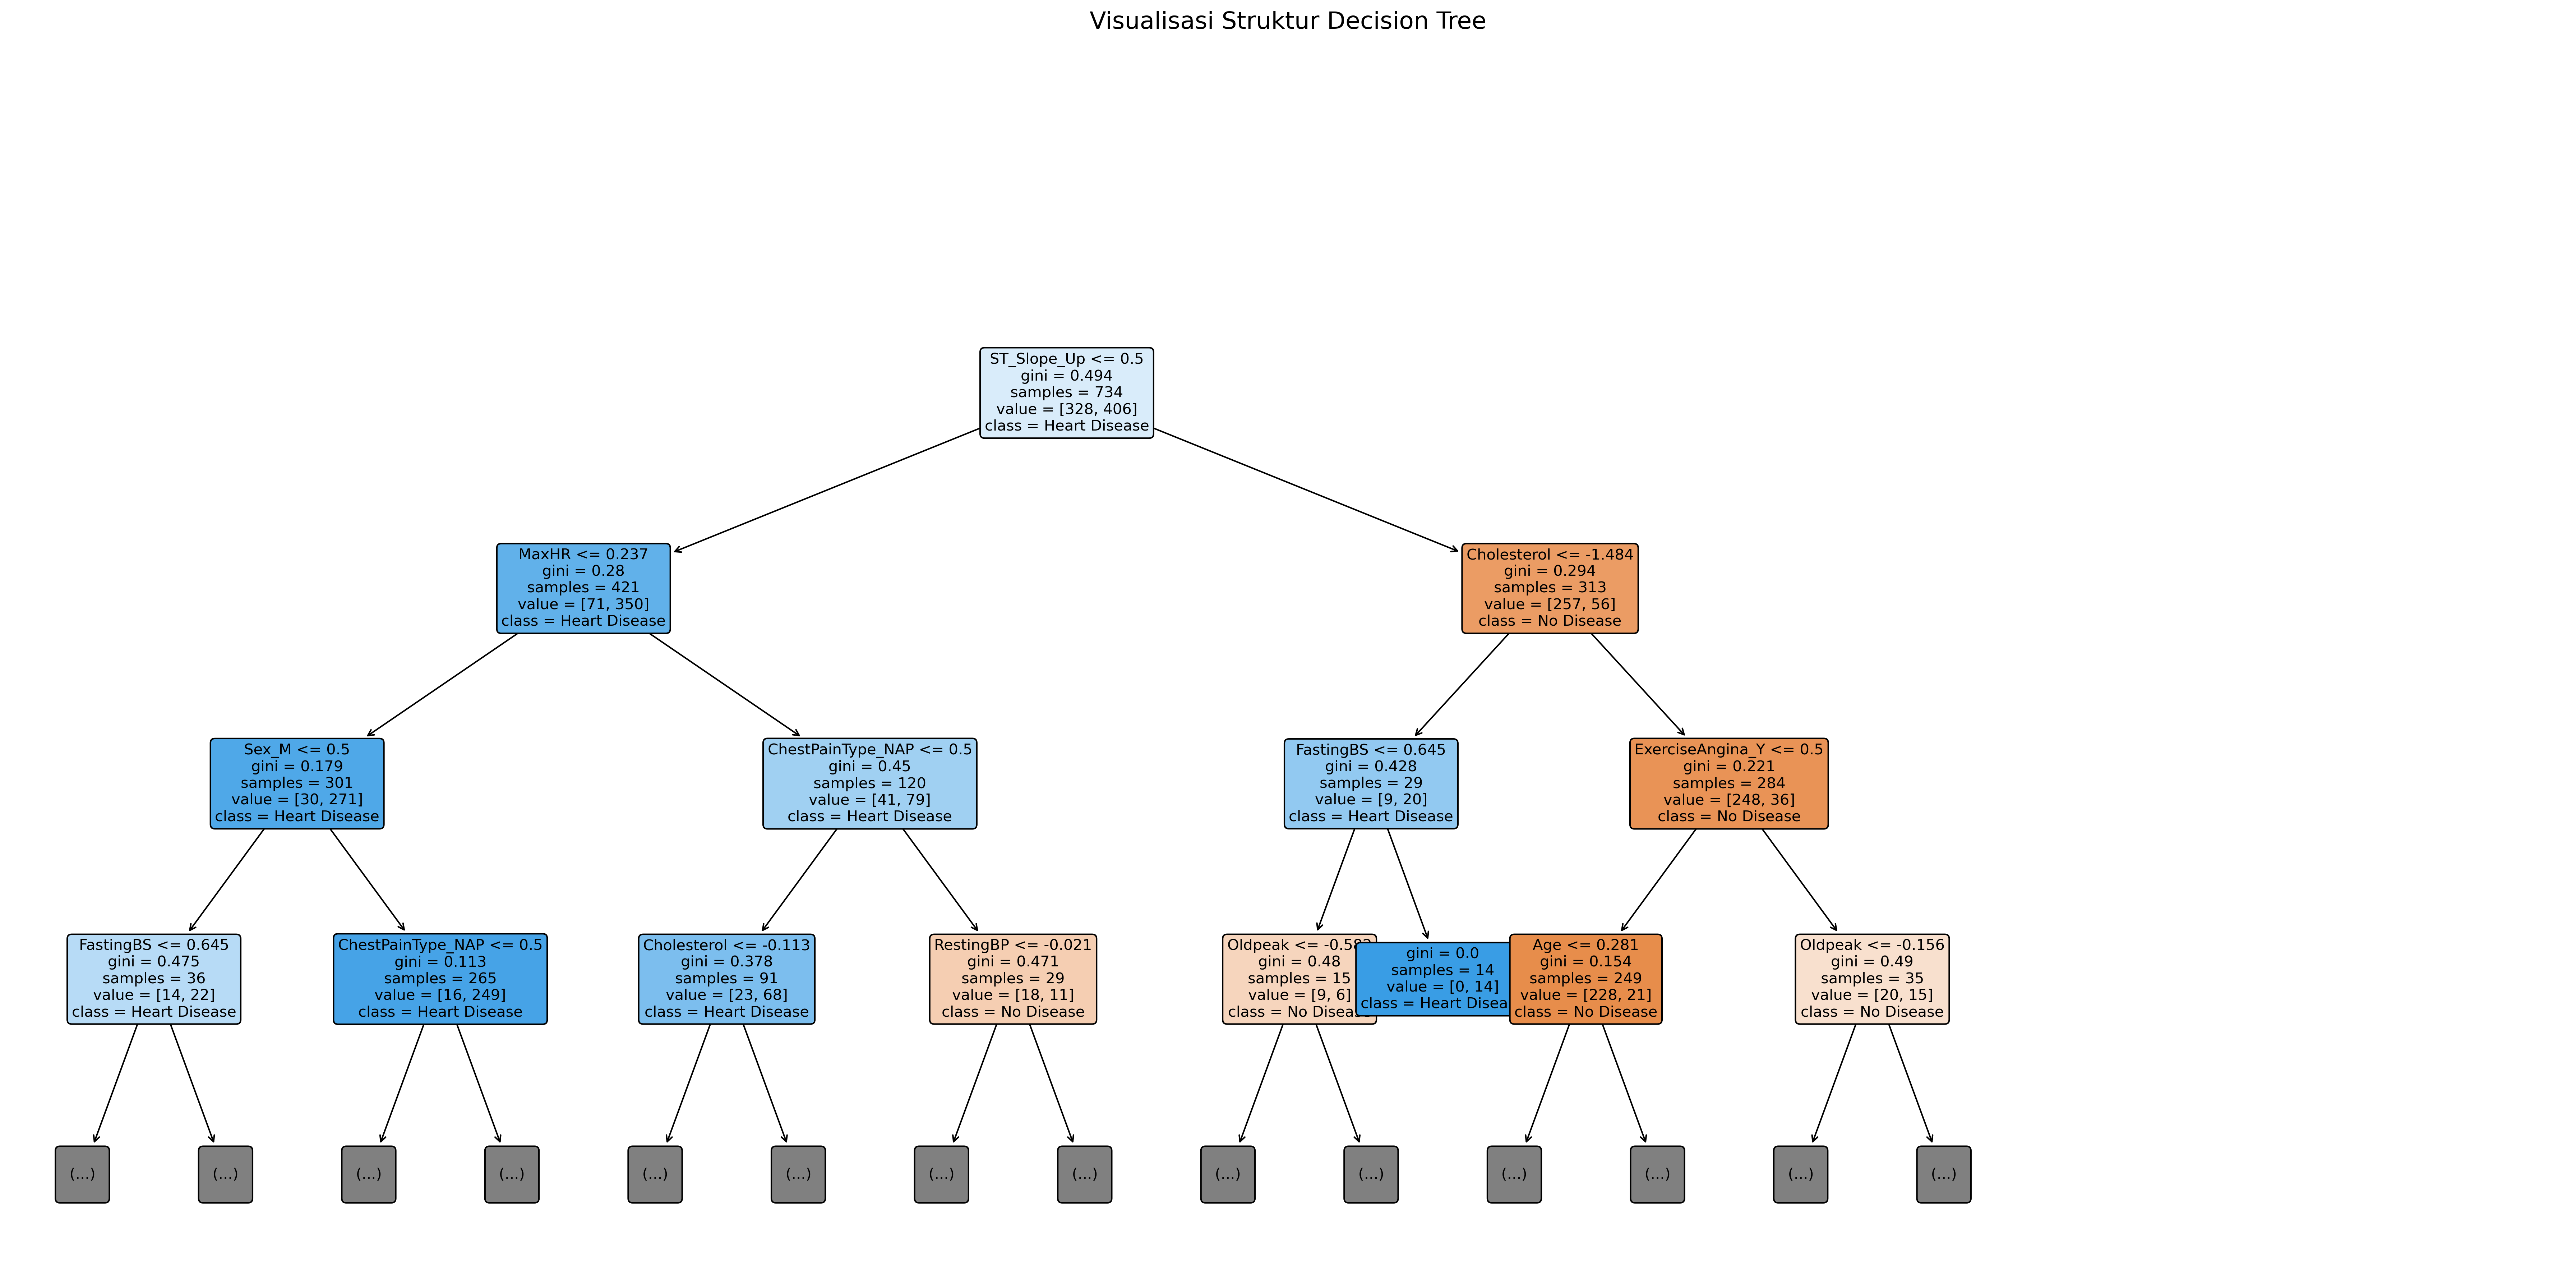

In [13]:
# Abraham_202431041
dt_model = dt_pipeline.named_steps['classifier']
cat_encoder = dt_pipeline.named_steps['preprocessor'].named_transformers_['cat']

if hasattr(cat_encoder, 'get_feature_names_out'):
    encoded_cat_cols = cat_encoder.get_feature_names_out(categorical_cols).tolist()
else:
    encoded_cat_cols = cat_encoder.get_feature_names(categorical_cols).tolist()

all_features = list(numerical_cols) + encoded_cat_cols

plt.figure(figsize=(24, 12), dpi=300)
plot_tree(
    dt_model, 
    feature_names=all_features, 
    class_names=['No Disease', 'Heart Disease'], 
    filled=True, 
    rounded=True,
    max_depth=3,
    fontsize=10
)
plt.title("Visualisasi Struktur Decision Tree", fontsize=16)
plt.tight_layout()
plt.show()

=== Model K-Nearest Neighbors (KNN) ===
Akurasi: 0.8859

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.83      0.87        82
           1       0.87      0.93      0.90       102

    accuracy                           0.89       184
   macro avg       0.89      0.88      0.88       184
weighted avg       0.89      0.89      0.89       184



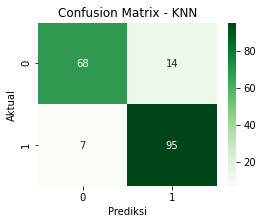

In [10]:
# Abraham_202431041
knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])

knn_pipeline.fit(X_train, y_train)

y_pred_knn = knn_pipeline.predict(X_test)
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("=== Model K-Nearest Neighbors (KNN) ===")
print(f"Akurasi: {knn_accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_knn))

plt.figure(figsize=(4, 3))
sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt='d', cmap='Greens')
plt.title('Confusion Matrix - KNN')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

=== Perbandingan Akurasi Model ===


,Model,Accuracy
0,Decision Tree,0.798913
1,K-Nearest Neighbors (KNN),0.885870


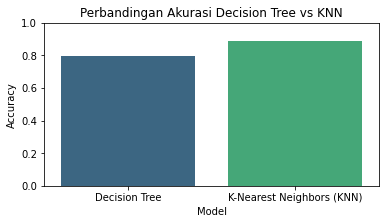

In [11]:
# Abraham_202431041
comparison = pd.DataFrame({
    'Model': ['Decision Tree', 'K-Nearest Neighbors (KNN)'],
    'Accuracy': [dt_accuracy, knn_accuracy]
})

print("=== Perbandingan Akurasi Model ===")
display(comparison)

plt.figure(figsize=(6, 3))
sns.barplot(x='Model', y='Accuracy', data=comparison, palette='viridis')
plt.ylim(0, 1.0)
plt.title('Perbandingan Akurasi Decision Tree vs KNN')
plt.show()